# 03 – Practice 1: PyTorch FashionMNIST Classification (notebook tổng hợp)

Notebook này chạy lại toàn bộ pipeline từ đầu đến cuối bằng code trong `src/`:

1. Tải dữ liệu và xem mẫu
2. So sánh ba kiến trúc (MLP, CNN, DeepCNN)
3. Huấn luyện mô hình với cấu hình tốt nhất đã chọn ở bước tinh chỉnh
4. Đánh giá (loss, accuracy, precision/recall/F1, confusion matrix)
5. Biểu đồ loss và ảnh dự đoán so với nhãn thật
6. Lưu và tải lại mô hình
7. Tổng hợp kết quả thử nghiệm đã chạy ở `experiments/`

Chạy từ thư mục `notebooks/`. Để notebook chạy nhanh trên CPU, bước 3 huấn luyện **`DEMO_EPOCHS` epoch**; kết quả đầy đủ (nhiều epoch hơn) nằm ở `results/tables/` và được hiển thị ở bước 7.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))   # để import được src.*

import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import (CLASS_NAMES, NUM_CLASSES, RANDOM_SEED, TABLES_DIR, FIGURES_DIR,
                        CHECKPOINT_DIR, ensure_dirs, set_seed, get_device)
from src.preprocessing.dataset import get_data_loaders
from src.models.neural_network import MLP, CNN, DeepCNN
from src.models.model_io import save_model, load_model
from src.training.trainer import fit
from src.evaluation.metrics import evaluate, predict_all
from src.visualization.plot_loss import plot_loss
from src.visualization.show_predictions import show_predictions

DEMO_EPOCHS = 3          # số epoch huấn luyện lại trong notebook này
ensure_dirs(); set_seed(RANDOM_SEED)
device = get_device()
print('PyTorch', torch.__version__, '| thiết bị:', device)

PyTorch 2.14.1 | thiết bị: cpu


## 1. Dữ liệu
FashionMNIST: 60.000 ảnh train, 10.000 ảnh test, ảnh xám 28×28, 10 lớp. Sau `ToTensor` + `Normalize((0.5,), (0.5,))` pixel nằm trong [-1, 1].

số mẫu train / test: 60000 / 10000
batch ảnh: (64, 1, 28, 28) | batch nhãn: (64,) torch.int64
pixel min / max: -1.0 / 1.0


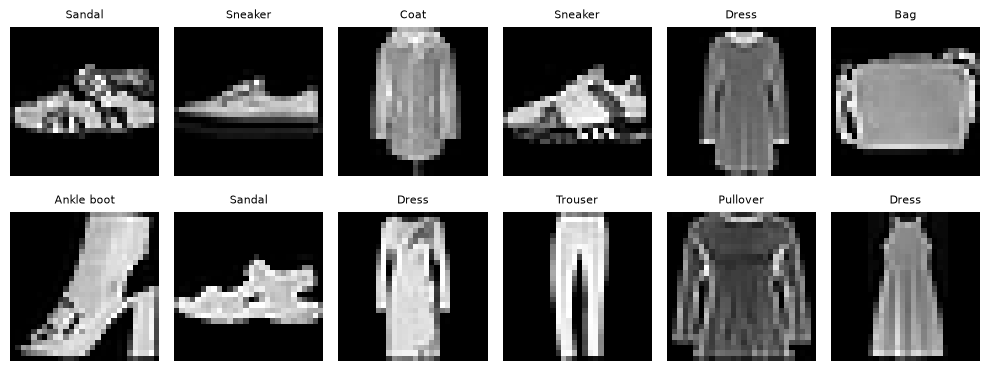

In [2]:
train_loader, test_loader = get_data_loaders()
images, labels = next(iter(train_loader))
print('số mẫu train / test:', len(train_loader.dataset), '/', len(test_loader.dataset))
print('batch ảnh:', tuple(images.shape), '| batch nhãn:', tuple(labels.shape), labels.dtype)
print('pixel min / max:', images.min().item(), '/', images.max().item())

fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap='gray'); ax.set_title(CLASS_NAMES[lab], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Ba kiến trúc
Số tham số của từng mô hình; đầu ra luôn là logits `(N, 10)`.

In [3]:
rows = []
for cls in (MLP, CNN, DeepCNN):
    m = cls()
    out = m(images[:2])
    rows.append({'model': cls.__name__, 'tham số': sum(p.numel() for p in m.parameters()),
                 'output shape': tuple(out.shape)})
pd.DataFrame(rows)

,model,tham số,output shape
0,MLP,235146,"(2, 10)"
1,CNN,421642,"(2, 10)"
2,DeepCNN,241546,"(2, 10)"


## 3. Huấn luyện với cấu hình tốt nhất
Cấu hình (mô hình, optimizer, learning rate, batch size, dropout) được đọc từ `results/tables/best_hyperparameter_summary.json`, là kết quả tinh chỉnh dựa trên **validation set**. Mỗi epoch: Forward → Loss → Backward → Optimize.

In [4]:
with open(TABLES_DIR / 'best_hyperparameter_summary.json', encoding='utf-8') as f:
    best = json.load(f)
cfg = {k: best[k] for k in ('experiment_id', 'model_name', 'optimizer_name', 'learning_rate',
                            'batch_size', 'dropout', 'momentum', 'weight_decay')}
print(cfg)

model_cls = {'mlp': MLP, 'cnn': CNN, 'deepcnn': DeepCNN}[cfg['model_name'].lower()]
set_seed(RANDOM_SEED)
train_loader, test_loader = get_data_loaders(batch_size=cfg['batch_size'])
model = (model_cls() if cfg['model_name'].lower() == 'mlp' else model_cls(dropout=cfg['dropout'])).to(device)
loss_fn = nn.CrossEntropyLoss()
if cfg['optimizer_name'].lower() == 'adam':
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
else:
    optimizer = torch.optim.SGD(model.parameters(), lr=cfg['learning_rate'],
                                momentum=cfg['momentum'], weight_decay=cfg['weight_decay'])

history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs=DEMO_EPOCHS, device=device)
pd.DataFrame(history)

{'experiment_id': 'TUNE-EPOCH-LONG', 'model_name': 'cnn', 'optimizer_name': 'adam', 'learning_rate': 0.001, 'batch_size': 64, 'dropout': 0.25, 'momentum': 0.9, 'weight_decay': 0.0}


epoch 1 | train_loss=0.5004 | train_accuracy=0.8195 | test_loss=0.3367 | test_accuracy=0.8742


epoch 2 | train_loss=0.3215 | train_accuracy=0.8829 | test_loss=0.2996 | test_accuracy=0.8899


epoch 3 | train_loss=0.2727 | train_accuracy=0.9020 | test_loss=0.2736 | test_accuracy=0.9019


,epoch,train_loss,train_accuracy,test_loss,test_accuracy
0,1,0.500426,0.819517,0.336652,0.8742
1,2,0.321462,0.882867,0.299561,0.8899
2,3,0.272683,0.902017,0.273639,0.9019


## 4. Đánh giá trên tập test

In [5]:
final = evaluate(model, test_loader, loss_fn, device)
print(f"test loss = {final['loss']:.4f} | test accuracy = {final['accuracy']:.4f}")

y_true, y_pred = predict_all(model, test_loader, device)
cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1                       # hàng = nhãn thật, cột = nhãn dự đoán
tp = cm.diag().float()
precision = tp / cm.sum(dim=0).clamp(min=1)
recall = tp / cm.sum(dim=1).clamp(min=1)
f1 = 2 * precision * recall / (precision + recall).clamp(min=1e-12)
pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1, 'support': cm.sum(dim=1)},
             index=CLASS_NAMES).round(4)

test loss = 0.2736 | test accuracy = 0.9019


,precision,recall,f1,support
T-shirt/top,0.7803,0.934,0.8503,1000
Trouser,0.9939,0.979,0.9864,1000
Pullover,0.9081,0.810,0.8562,1000
Dress,0.9068,0.885,0.8957,1000
Coat,0.8310,0.875,0.8524,1000
Sandal,0.9907,0.963,0.9767,1000
Shirt,0.7503,0.661,0.7028,1000
Sneaker,0.9323,0.978,0.9546,1000
Bag,0.9703,0.981,0.9756,1000
Ankle boot,0.9685,0.953,0.9607,1000


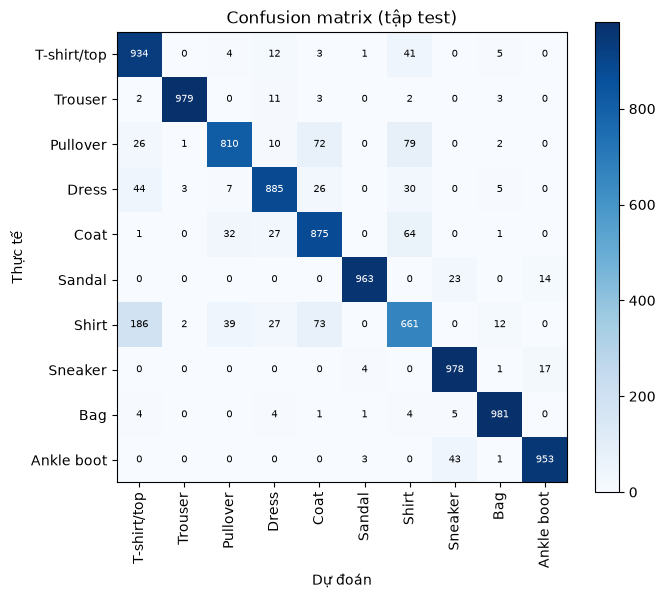

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set(xlabel='Dự đoán', ylabel='Thực tế', title='Confusion matrix (tập test)')
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im); plt.tight_layout(); plt.show()

## 5. Biểu đồ loss và ảnh dự đoán so với nhãn thật

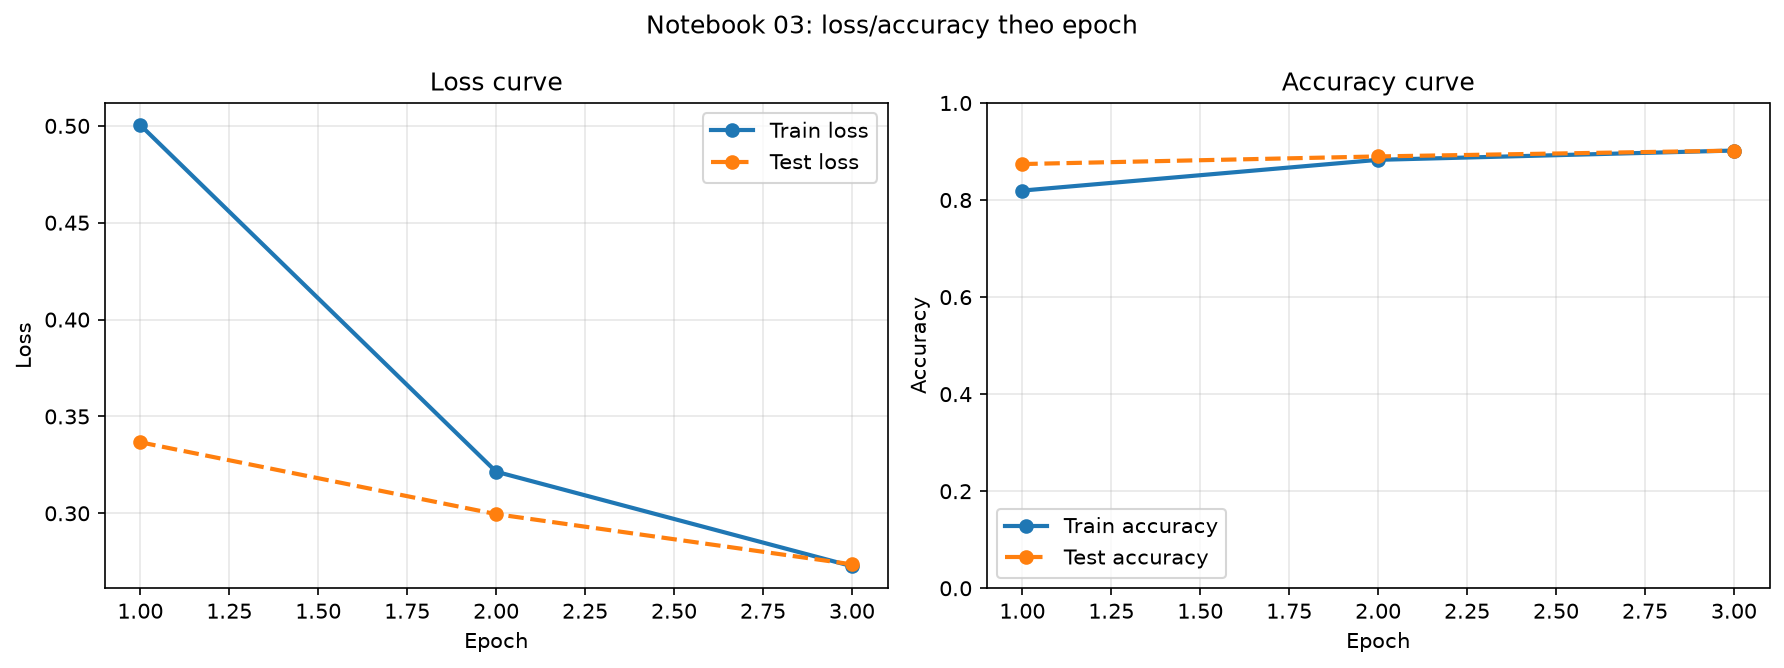

In [7]:
loss_png = plot_loss(history, FIGURES_DIR / 'notebook03_loss.png', title='Notebook 03: loss/accuracy theo epoch')
display(Image(filename=str(loss_png)))

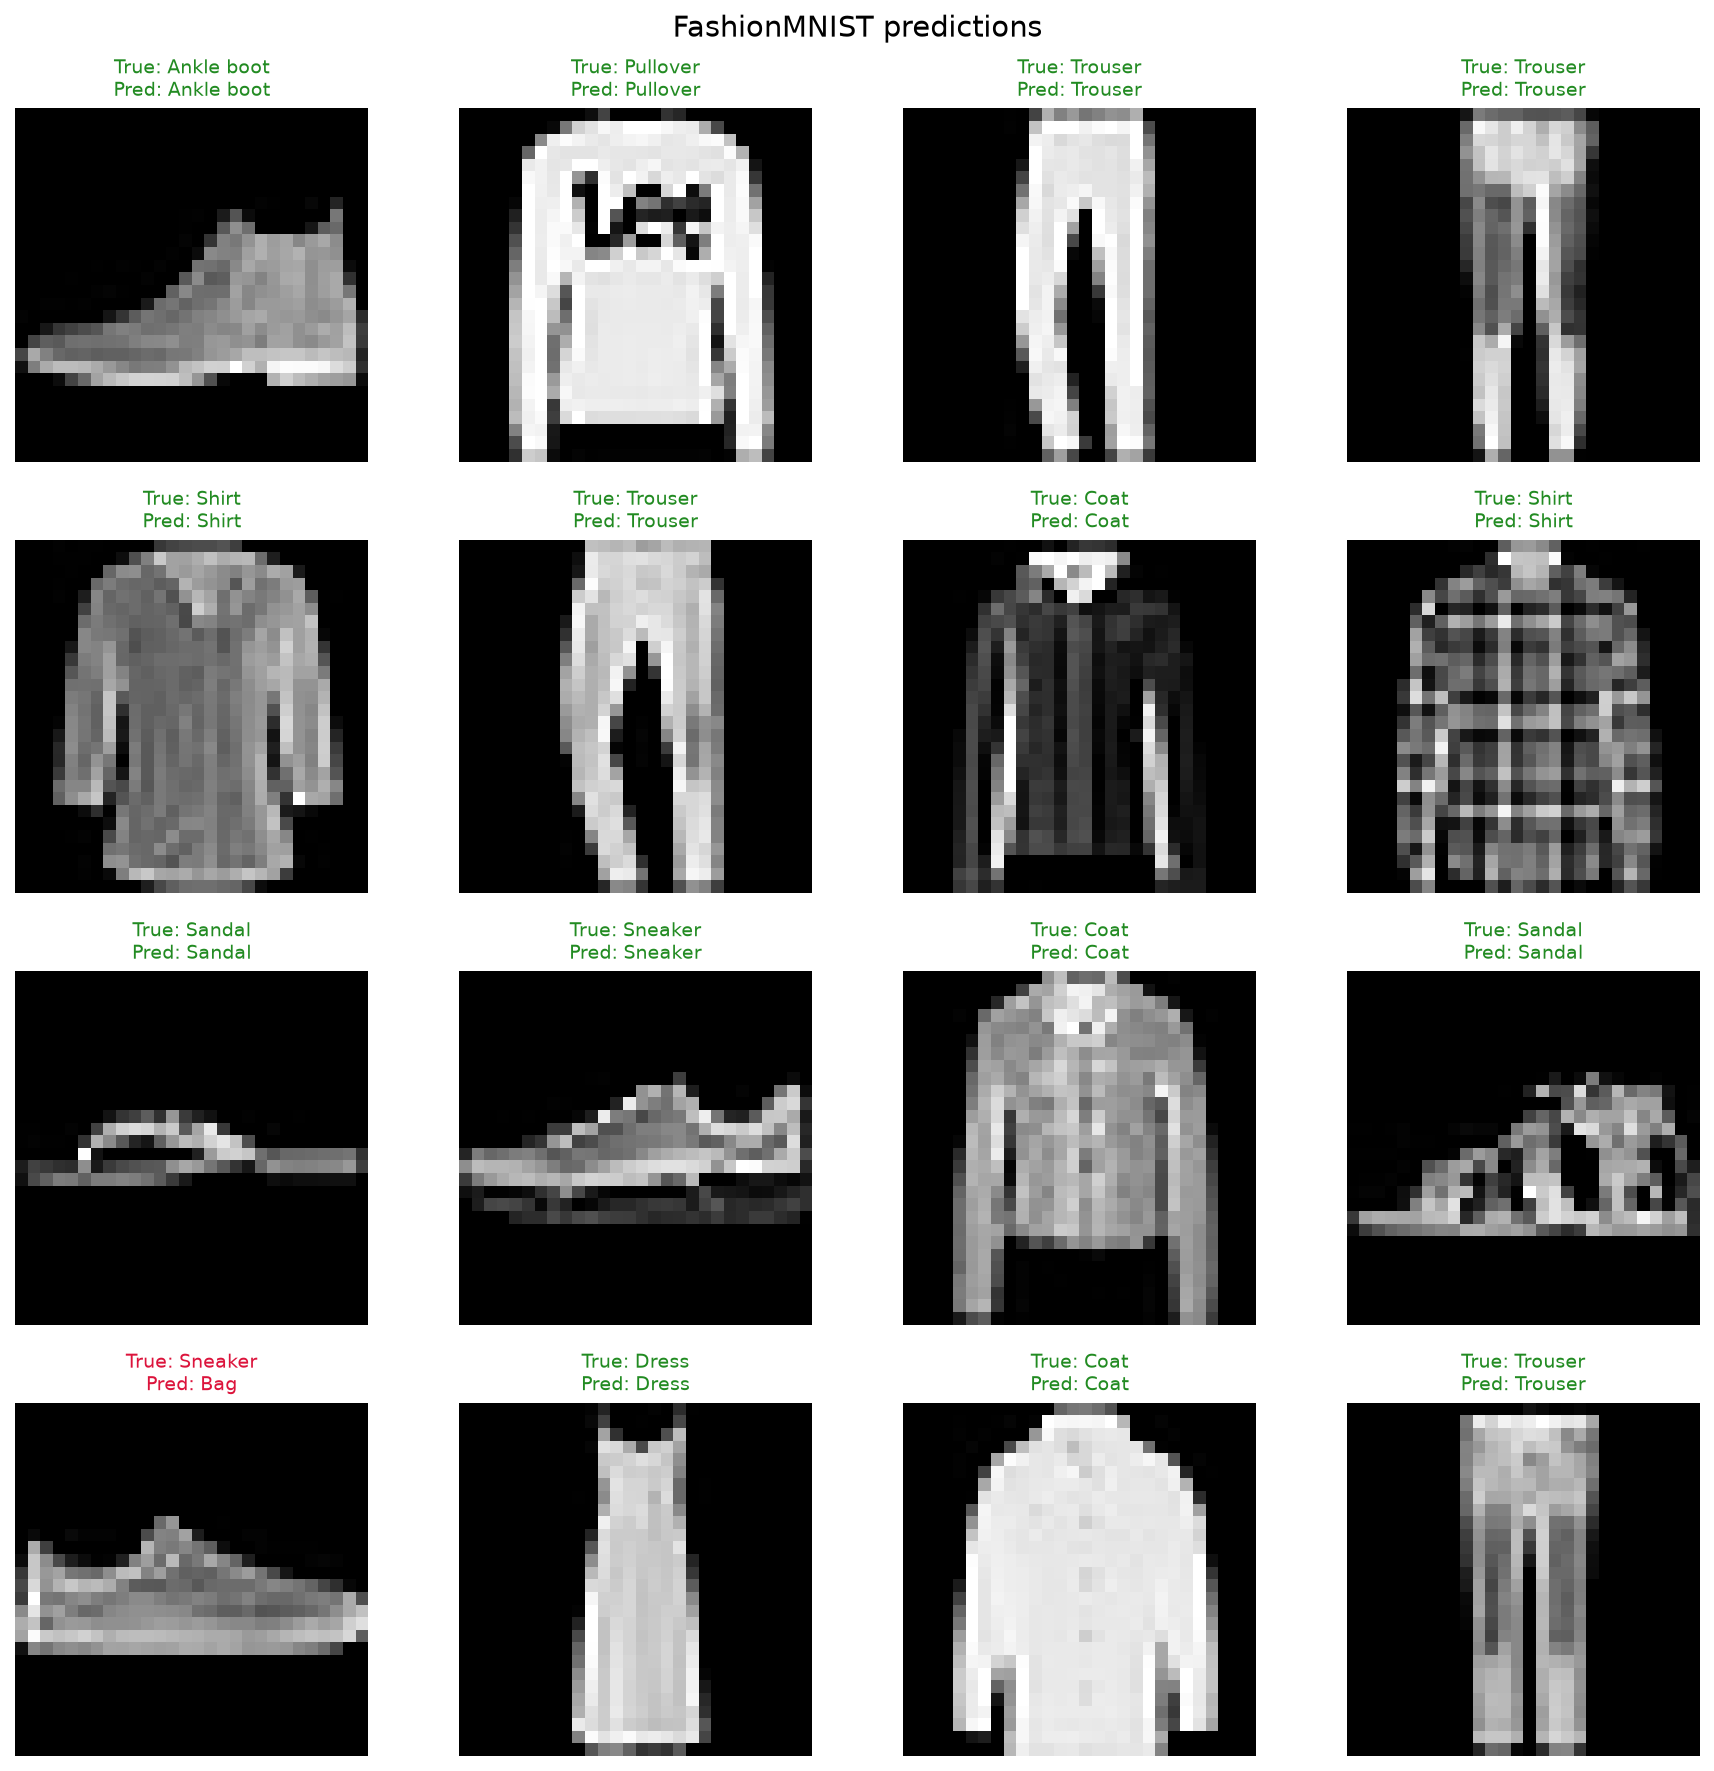

In [8]:
pred_png = show_predictions(model, test_loader, device=device, num_images=16,
                            save_path=FIGURES_DIR / 'notebook03_predictions.png')
display(Image(filename=str(pred_png)))

## 6. Lưu và tải lại mô hình
Mô hình tải lại phải cho đúng accuracy như trước khi lưu.

In [9]:
ckpt = save_model(model, CHECKPOINT_DIR / 'notebook03_model.pth')
reloaded = (model_cls() if cfg['model_name'].lower() == 'mlp' else model_cls(dropout=cfg['dropout']))
reloaded = load_model(reloaded, ckpt, device)
after = evaluate(reloaded, test_loader, loss_fn, device)
print('accuracy trước khi lưu :', final['accuracy'])
print('accuracy sau khi tải lại:', after['accuracy'])
assert abs(final['accuracy'] - after['accuracy']) < 1e-9
print('OK: lưu/tải khớp.')

accuracy trước khi lưu : 0.9019
accuracy sau khi tải lại: 0.9019
OK: lưu/tải khớp.


## 7. Tổng hợp kết quả thử nghiệm (đã chạy ở `experiments/`)

In [10]:
comp = pd.read_csv(TABLES_DIR / 'model_comparison.csv')
print('So sánh kiến trúc (cùng điều kiện: Adam, lr=1e-3, batch 64):')
comp

So sánh kiến trúc (cùng điều kiện: Adam, lr=1e-3, batch 64):


,model,total_params,trainable_params,epochs,train_time_s,test_loss,test_accuracy
0,MLP,235146,235146,5,35.9,0.3421,0.8790
1,CNN,421642,421642,5,181.0,0.2440,0.9100
2,DeepCNN,241546,241546,5,229.9,0.2470,0.9083


In [11]:
tune = pd.read_csv(TABLES_DIR / 'hyperparameter_results.csv')
cols = ['experiment_id', 'purpose', 'learning_rate', 'batch_size', 'epochs', 'optimizer_name', 'dropout',
        'best_val_accuracy', 'final_train_accuracy', 'duration_seconds']
print('Tinh chỉnh hyperparameters (chọn theo validation accuracy):')
tune[cols].round(4)

Tinh chỉnh hyperparameters (chọn theo validation accuracy):


,experiment_id,purpose,learning_rate,batch_size,epochs,optimizer_name,dropout,best_val_accuracy,final_train_accuracy,duration_seconds
0,TUNE-EPOCH-LONG,Nhiều epoch hơn baseline,0.0010,64,6,adam,0.25,0.9160,0.9249,224.62
1,TUNE-DROP-0,Không dùng dropout,0.0010,64,3,adam,0.00,0.9095,0.9125,119.92
2,TUNE-DROP-20,Dropout nhẹ,0.0010,64,3,adam,0.20,0.9083,0.8998,124.48
3,TUNE-LR-HIGH,Learning rate cao,0.0030,64,3,adam,0.25,0.9065,0.9060,103.77
4,TUNE-BATCH-32,Batch size nhỏ,0.0010,32,3,adam,0.25,0.9058,0.9073,107.47
5,TUNE-BASE,Baseline CNN + Adam,0.0010,64,3,adam,0.25,0.9058,0.8974,109.84
6,TUNE-BATCH-128,Batch size lớn,0.0010,128,3,adam,0.25,0.9018,0.8931,104.36
7,TUNE-DROP-50,Dropout mạnh,0.0010,64,3,adam,0.50,0.9003,0.8806,110.12
8,TUNE-OPT-SGD,So sánh SGD momentum với Adam,0.0100,64,3,sgd,0.25,0.8975,0.8826,104.15
9,TUNE-LR-LOW,Learning rate thấp,0.0003,64,3,adam,0.25,0.8932,0.8790,109.27


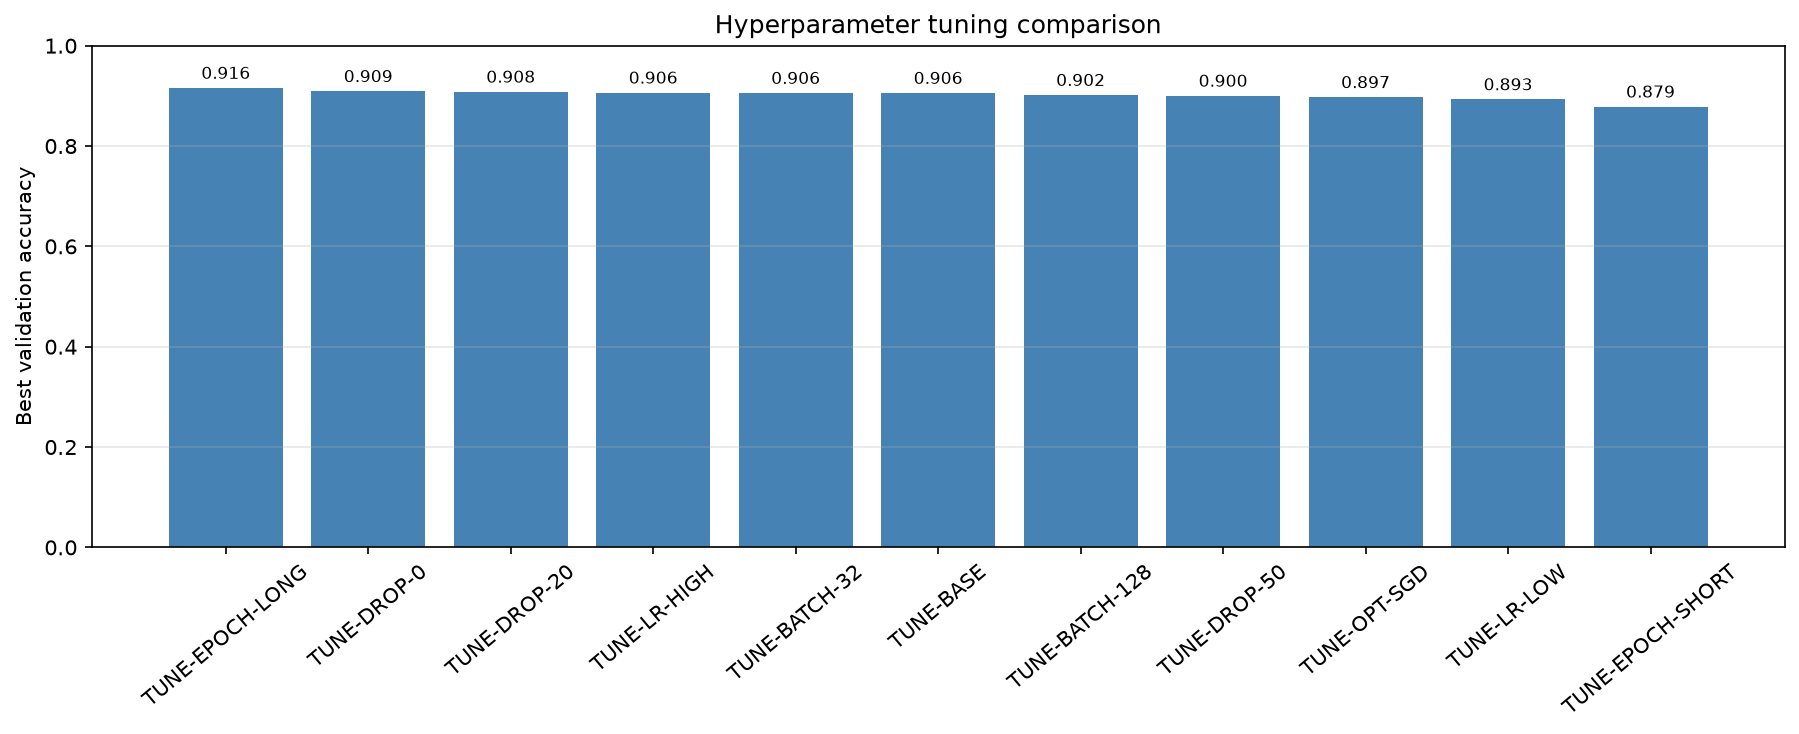

In [12]:
display(Image(filename=str(FIGURES_DIR / 'hyperparameter_comparison.png')))

## Kết luận
Số liệu cụ thể, phân tích và nhận xét nằm trong `docs/06_results/` (đánh giá, thử nghiệm, kết luận) và báo cáo cuối ở `results/reports/`. Notebook này đóng vai trò chạy lại được toàn bộ pipeline để kiểm chứng kết quả.